<a href="https://colab.research.google.com/github/JuanitaRozo/REINFORCEMENT-LEARNING/blob/main/REINFORCEMENT_LEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Episodios de entrenamiento: 1000
Recompensa media, primeros 100 episodios: -2.09
Recompensa media, últimos 100 episodios: 9.29
Promedio de pasos, últimos 100 episodios: 6.46
Ruta greedy final: [(0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (3, 2), (3, 3)]
Recompensa greedy final: 9.50


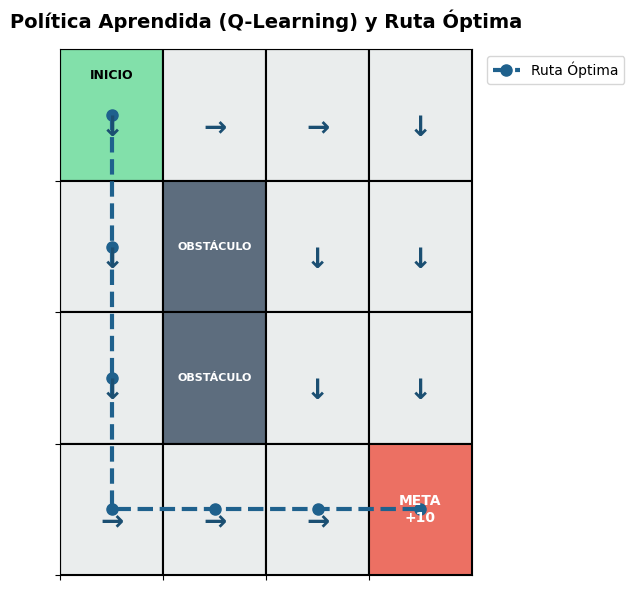

In [8]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

GRID_SIZE = 4
START = (0, 0)
GOAL = (3, 3)
OBSTACLES = {(1, 1), (2, 1)}
ACTIONS = [(-1,0), (1,0), (0,-1), (0,1)]

Q = np.zeros((GRID_SIZE, GRID_SIZE, 4))

alpha = 0.10
gamma = 0.95
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

def step(state, action):
    r, c = state
    dr, dc = ACTIONS[action]
    nr, nc = r + dr, c + dc

    if (nr < 0 or nr >= GRID_SIZE or
        nc < 0 or nc >= GRID_SIZE or
        (nr, nc) in OBSTACLES):
        return state, -1.0, False

    next_state = (nr, nc)

    if next_state == GOAL:
        return next_state, 10.0, True

    return next_state, -0.1, False

# Contenedores para almacenar las métricas solicitadas
recompensas_por_episodio = []
pasos_por_episodio = []
total_episodes = 1000

for episode in range(total_episodes):
    state = START
    total_reward = 0
    steps = 0

    for step_idx in range(100):
        if np.random.rand() < epsilon:
            action = np.random.randint(4)
        else:
            action = np.argmax(Q[state[0], state[1], :])

        next_state, reward, done = step(state, action)
        total_reward += reward
        steps += 1

        best_next_q = 0 if done else np.max(
            Q[next_state[0], next_state[1], :]
        )

        target = reward + gamma * best_next_q

        Q[state[0], state[1], action] += alpha * (
            target - Q[state[0], state[1], action]
        )

        state = next_state

        if done:
            break

    recompensas_por_episodio.append(total_reward)
    pasos_por_episodio.append(steps)
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

# Evaluación final (Ruta Greedy)
state = START
path = [state]
reward_greedy_final = 0

for _ in range(30):
    action = np.argmax(Q[state[0], state[1], :])
    next_state, reward, done = step(state, action)
    reward_greedy_final += reward
    state = next_state
    path.append(state)

    if done:
        break

# Cálculo de métricas requeridas
recompensa_media_primeros_100 = np.mean(recompensas_por_episodio[:100])
recompensa_media_ultimos_100 = np.mean(recompensas_por_episodio[-100:])
promedio_pasos_ultimos_100 = np.mean(pasos_por_episodio[-100:])

# Imprimir métricas
print(f"Episodios de entrenamiento: {total_episodes}")
print(f"Recompensa media, primeros 100 episodios: {recompensa_media_primeros_100:.2f}")
print(f"Recompensa media, últimos 100 episodios: {recompensa_media_ultimos_100:.2f}")
print(f"Promedio de pasos, últimos 100 episodios: {promedio_pasos_ultimos_100:.2f}")
print("Ruta greedy final:", path)
print(f"Recompensa greedy final: {reward_greedy_final:.2f}")

# Crear la figura para la representación gráfica
fig, ax = plt.subplots(figsize=(6, 6))

# Dibujar cada una de las celdas del Gridworld
for r in range(GRID_SIZE):
    for c in range(GRID_SIZE):
        # Definir color de fondo según la celda
        if (r, c) == START:
            color = '#82E0AA'  # Verde
        elif (r, c) == GOAL:
            color = '#EC7063'  # Rojo
        elif (r, c) in OBSTACLES:
            color = '#5D6D7E'  # Gris oscuro
        else:
            color = '#EAEDED'  # Gris claro

        # Dibujar el rectángulo que representa la celda
        rect = plt.Rectangle((c, GRID_SIZE - 1 - r), 1, 1, facecolor=color, edgecolor='black', linewidth=1.5)
        ax.add_patch(rect)

        # Agregar texto informativo según la celda
        if (r, c) == START:
            ax.text(c + 0.5, GRID_SIZE - 1 - r + 0.8, 'INICIO', va='center', ha='center', fontsize=9, fontweight='bold')
        elif (r, c) == GOAL:
            ax.text(c + 0.5, GRID_SIZE - 1 - r + 0.5, 'META\n+10', va='center', ha='center', fontsize=10, fontweight='bold', color='white')
            continue
        elif (r, c) in OBSTACLES:
            ax.text(c + 0.5, GRID_SIZE - 1 - r + 0.5, 'OBSTÁCULO', va='center', ha='center', fontsize=8, color='white', fontweight='bold')
            continue

        # Obtener la mejor acción aprendida en esta celda
        best_action = np.argmax(Q[r, c, :])
        dr, dc = ACTIONS[best_action]

        # Dibujar flechas representando la política en celdas transitables
        arrow_symbols = {(-1, 0): '↑', (1, 0): '↓', (0, -1): '←', (0, 1): '→'}
        symbol = arrow_symbols[(dr, dc)]
        ax.text(c + 0.5, GRID_SIZE - 1 - r + 0.4, symbol, va='center', ha='center', fontsize=20, fontweight='bold', color='#1B4F72')

# Dibujar la ruta final aprendida superpuesta
path_x = [c + 0.5 for (r, c) in path]
path_y = [GRID_SIZE - 1 - r + 0.5 for (r, c) in path]
ax.plot(path_x, path_y, color='#1F618D', linewidth=3, linestyle='--', marker='o', markersize=8, label='Ruta Óptima')

# Ajustar los límites de la gráfica y ocultar los ejes
ax.set_xlim(0, GRID_SIZE)
ax.set_ylim(0, GRID_SIZE)
ax.set_xticks(range(GRID_SIZE))
ax.set_yticks(range(GRID_SIZE))
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.grid(False)

plt.title('Política Aprendida (Q-Learning) y Ruta Óptima', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()